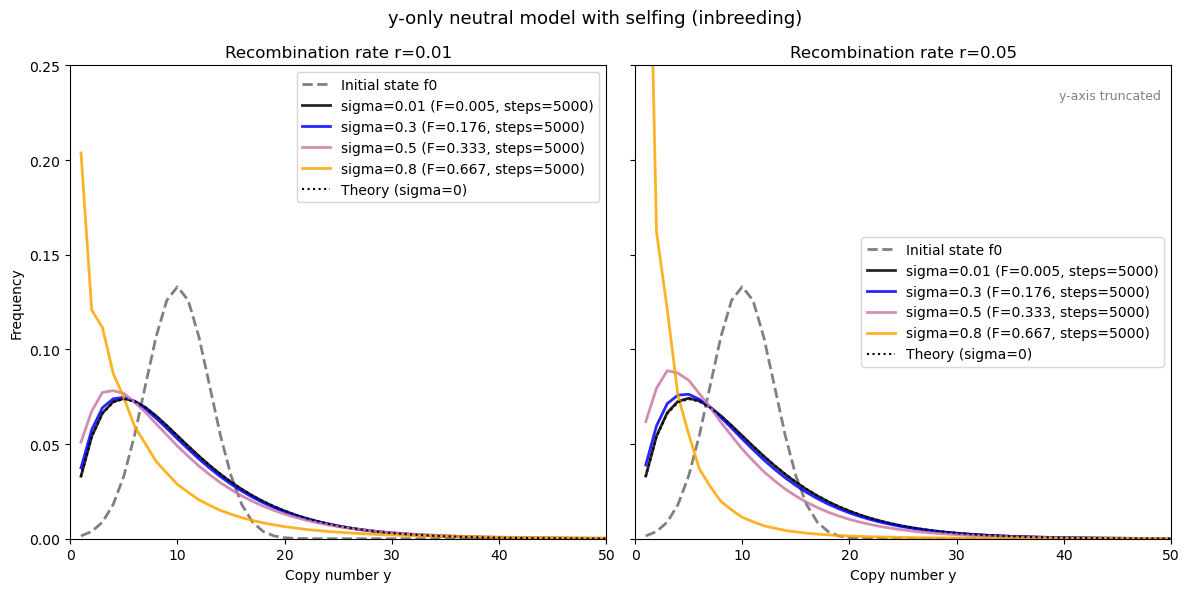

In [20]:
import numpy as np
import matplotlib.pyplot as plt

# Trapezoidal kernel tensor

def trapez_tensor(n: int) -> np.ndarray:
    """
    Build T[k,i,j] = T(k | y1=i+1, y2=j+1) for k,i,j in {1..n}.
    Uses Otto-style trapezoidal kernel.
    """
    K  = np.arange(1, n + 1)[:, None, None]     # k index (1..n)
    Y1 = np.arange(1, n + 1)[None, :, None]     # y1 (1..n)
    Y2 = np.arange(1, n + 1)[None, None, :]     # y2 (1..n)

    ysum  = Y1 + Y2
    ymin  = np.minimum(Y1, Y2)
    ymax  = np.maximum(Y1, Y2)
    valid = (K <= (ysum - 1))

    val = np.where(K <= ymin, K,
          np.where(K <= ymax, ymin,
          np.where(valid, ysum - K, 0.0)))

    denom = (Y1 * Y2).astype(float)
    T = np.where(valid, val / denom, 0.0)
    return T


# Theory for sigma=0 (outcrossing)

def stationary_theory_from_mean(E0: float, n: int) -> np.ndarray:
    y = np.arange(1, n + 1, dtype=float)
    p = y * np.exp(-2.0 * y / E0)
    return p / p.sum()


# Inbreeding coefficient F under partial selfing

def update_F(F: float, sigma: float) -> float:
    # Otto lecture: F_{t+1} = (sigma/2) * (1 + F_t)
    sigma = float(np.clip(sigma, 0.0, 1.0))
    return 0.5 * sigma * (1.0 + F)

def F_equilibrium(sigma: float) -> float:
    sigma = float(np.clip(sigma, 0.0, 1.0))
    return 1.0 if sigma >= 1.0 else sigma / (2.0 - sigma)

# Genotype closure g(a,b) from (f, F)

def genotype_closure_from_fF(f: np.ndarray, F: float) -> np.ndarray:
    """
    Build a symmetric genotype frequency matrix g[a,b] (ordered-pair representation)
    from allele/copy-number frequencies f and inbreeding coefficient F.

    We store full n x n matrix (symmetric), with sum(g)=1.

    Ordered-pair closure:
      g(a,a) = f(a)^2 + F f(a)(1-f(a))
      g(a,b) = (1-F) f(a) f(b)   for a != b
    """
    f = f / f.sum()
    F = float(np.clip(F, 0.0, 1.0))
    n = f.size

    outer = np.outer(f, f)
    g = (1.0 - F) * outer  # sets all entries including diagonal; we overwrite diagonal next

    diag = f * f + F * f * (1.0 - f)
    np.fill_diagonal(g, diag)

    # enforce symmetry (numerical hygiene)
    g = 0.5 * (g + g.T)

    # renormalize (tiny numerical drift)
    g /= g.sum()
    return g


# One-step update for f

def f_post_neutral_selfing_closure(
    f_prior: np.ndarray,
    r: float,
    sigma: float,
    T: np.ndarray,
    F: float
) -> np.ndarray:
    """
    Deterministic update:
      f_{t+1} = (1-r) f_t + r * [(1-sigma) outcross + sigma selfed]
    where
      outcross(k) = sum_{i,j} f(i)f(j)T(k|i,j)
      selfed(k)   = sum_{a,b} g(a,b)T(k|a,b)  with g from closure (f,F)
    """
    f = f_prior / f_prior.sum()
    sigma = float(np.clip(sigma, 0.0, 1.0))

    # outcross term 
    outcross = np.einsum('kij,i,j->k', T, f, f, optimize=True)

    # selfing term with heterozygotes allowed via genotype closure
    g = genotype_closure_from_fF(f, F)
    selfed = np.einsum('kij,ij->k', T, g, optimize=True)

    recomb = (1.0 - sigma) * outcross + sigma * selfed
    f_post = (1.0 - r) * f + r * recomb
    return f_post / f_post.sum()


def iterate_selfing_closure(
    f0: np.ndarray,
    r: float,
    sigma: float,
    T: np.ndarray,
    tol: float = 1e-9,
    max_iter: int = 5000,
    use_F_equilibrium: bool = False
):
    """
    Iterate (f, F) deterministically until convergence.

    If use_F_equilibrium=True, we fix F=F*(sigma) from the start (faster).
    Otherwise, we iterate F via update_F.
    """
    f = f0 / f0.sum()
    sigma = float(np.clip(sigma, 0.0, 1.0))

    F = F_equilibrium(sigma) if use_F_equilibrium else 0.0

    for i in range(max_iter):
        F_new = F if use_F_equilibrium else update_F(F, sigma)
        f_new = f_post_neutral_selfing_closure(f, r, sigma, T, F_new)

        if np.abs(f_new - f).sum() < tol and (use_F_equilibrium or abs(F_new - F) < tol):
            return f_new, F_new, i

        f, F = f_new, F_new

    return f, F, max_iter


# produce plot

if __name__ == "__main__":
    n = 80
    y = np.arange(1, n + 1)
    T = trapez_tensor(n)

    f0 = np.exp(-((y - 10.0) ** 2) / (2 * 3.0 ** 2))
    f0 /= f0.sum()

    E0 = np.sum(y * f0)
    theory = stationary_theory_from_mean(E0, n)

    recomb_rates  = [0.01, 0.05]
    selfing_rates = [0.01, 0.3, 0.5, 0.8]
    colors        = ["black", "blue", "#CC79A7", "orange"]


    USE_F_EQ = False #False when we update the F

    fig, axes = plt.subplots(1, 2, figsize=(12, 6), sharey=True)
    for ax, r in zip(axes, recomb_rates):
        ax.plot(y, f0, "gray", linestyle="--", lw=2, label="Initial state f0")

        for sigma, col in zip(selfing_rates, colors):
            f_eq, F_eq, steps = iterate_selfing_closure(
                f0, r, sigma, T,
                use_F_equilibrium=USE_F_EQ
            )
            ax.plot(
                y, f_eq,
                color=col, lw=2, alpha=0.85,
                label=f"sigma={sigma} (F={F_eq:.3f}, steps={steps})"
            )

        ax.plot(y, theory, "k:", lw=1.5, label="Theory (sigma=0)")
        ax.set_title(f"Recombination rate r={r}")
        ax.set_xlabel("Copy number y")
        ax.set_xlim(0, 50)
        ax.set_ylim(0, 0.25)  # truncation
        ax.legend()

    axes[0].set_ylabel("Frequency")
    axes[1].text(
        0.98, 0.95,
        "y-axis truncated",
        transform=axes[1].transAxes,
        ha="right", va="top",
        fontsize=9, color="gray"
    )

    fig.suptitle("y-only neutral model with selfing (inbreeding)", fontsize=13)
    plt.tight_layout()
    plt.savefig("y_only_selfing_inbreeding_co.png", dpi=300, bbox_inches="tight")
    plt.show()